# OSTIA SST Icechunk Append Demo

Reads the OSTIA-UKMO-L4-GLOB-REP-v2.0 virtual Icechunk store and visualises its current state.
Run the top cells to snapshot **before**, send SQS messages in the background, then re-run the **After** cells to see the store grow.

In [1]:
import os
import warnings
import earthaccess
import icechunk
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

warnings.filterwarnings("ignore")

# ---- CONFIG ----
STORE_BUCKET  = "podaac-sit-services-cloud-optimizer"
STORE_PREFIX  = "virtual_collections/simon_demo_append/OSTIA-UKMO-L4-GLOB-REP-v2.0.icechunk_v2.https/"
VCC_PREFIX    = "https://archive.podaac.earthdata.nasa.gov/podaac-ops-cumulus-protected/"
AWS_PROFILE   = "service-sit"
REGION        = "us-west-2"

os.environ["AWS_PROFILE"] = AWS_PROFILE


def open_store():
    storage = icechunk.s3_storage(bucket=STORE_BUCKET, prefix=STORE_PREFIX, region=REGION)
    edl_token = earthaccess.get_edl_token()
    config = icechunk.Repository.fetch_config(storage)
    config.set_virtual_chunk_container(
        icechunk.VirtualChunkContainer(
            VCC_PREFIX,
            icechunk.http_store(
                headers={"Authorization": f"Bearer {edl_token['access_token']}"}
            ),
        )
    )
    repo = icechunk.Repository.open(
        storage, config=config,
        authorize_virtual_chunk_access={VCC_PREFIX: icechunk.credentials.HttpAccess},
    )
    return xr.open_zarr(repo.readonly_session(branch="main").store,
                        consolidated=False, decode_times=True)


def plot_sst(ds, title):
    sst = ds["analysed_sst"].isel(time=-1).values - 273.15
    t   = str(ds.time.values[-1])[:10]
    n   = ds.sizes["time"]
    fig, ax = plt.subplots(figsize=(14, 6))
    img = ax.imshow(sst, origin="lower", aspect="auto",
                    extent=[-180, 180, -90, 90],
                    cmap="RdYlBu_r", vmin=-2, vmax=32, interpolation="nearest")
    plt.colorbar(img, ax=ax, label="SST (°C)", shrink=0.7)
    ax.set_title(f"{title}  |  last step: {t}  ({n} total steps)")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    plt.tight_layout()
    plt.show()


def plot_time_axis(ds, new_from=None, title="Time axis"):
    times = ds["time"].values
    fig, ax = plt.subplots(figsize=(12, 2))
    if new_from is not None:
        ax.scatter(times[:new_from], np.ones(new_from), s=10,
                   color="steelblue", alpha=0.5, label=f"Original ({new_from})", zorder=2)
        ax.scatter(times[new_from:], np.ones(len(times) - new_from), s=40,
                   color="tomato", alpha=1.0, label=f"Appended ({len(times) - new_from})", zorder=3)
        ax.legend(loc="upper left")
    else:
        ax.scatter(times, np.ones(len(times)), s=10, color="steelblue", alpha=0.6)
    ax.set_yticks([])
    ax.set_xlabel("Time")
    ax.set_title(f"{title}  ({len(times)} steps)")
    plt.tight_layout()
    plt.show()

In [2]:
auth = earthaccess.login()
print("Authenticated:", auth.authenticated)

Authenticated: True


## Before — current store state

  2026-10-26T15:41:36.774720Z  WARN aws_runtime::env_config::normalize: profile [claude] ignored; sections in the AWS config file (other than [default]) must have a prefix i.e. [profile my-profile]
    at /Users/runner/.cargo/registry/src/index.crates.io-1949cf8c6b5b557f/aws-runtime-1.7.2/src/env_config/normalize.rs:121

  2026-10-26T15:41:36.774761Z  WARN aws_runtime::env_config::normalize: profile [cumulus-sit] ignored; sections in the AWS config file (other than [default]) must have a prefix i.e. [profile my-profile]
    at /Users/runner/.cargo/registry/src/index.crates.io-1949cf8c6b5b557f/aws-runtime-1.7.2/src/env_config/normalize.rs:121

  2026-10-26T15:41:36.774767Z  WARN aws_runtime::env_config::normalize: profile [service-uat] ignored; sections in the AWS config file (other than [default]) must have a prefix i.e. [profile my-profile]
    at /Users/runner/.cargo/registry/src/index.crates.io-1949cf8c6b5b557f/aws-runtime-1.7.2/src/env_config/normalize.rs:121

  2026-10-26T15:41:36

500 steps  |  1982-01-01T12:00:00.000000000 → 1983-05-15T12:00:00.000000000


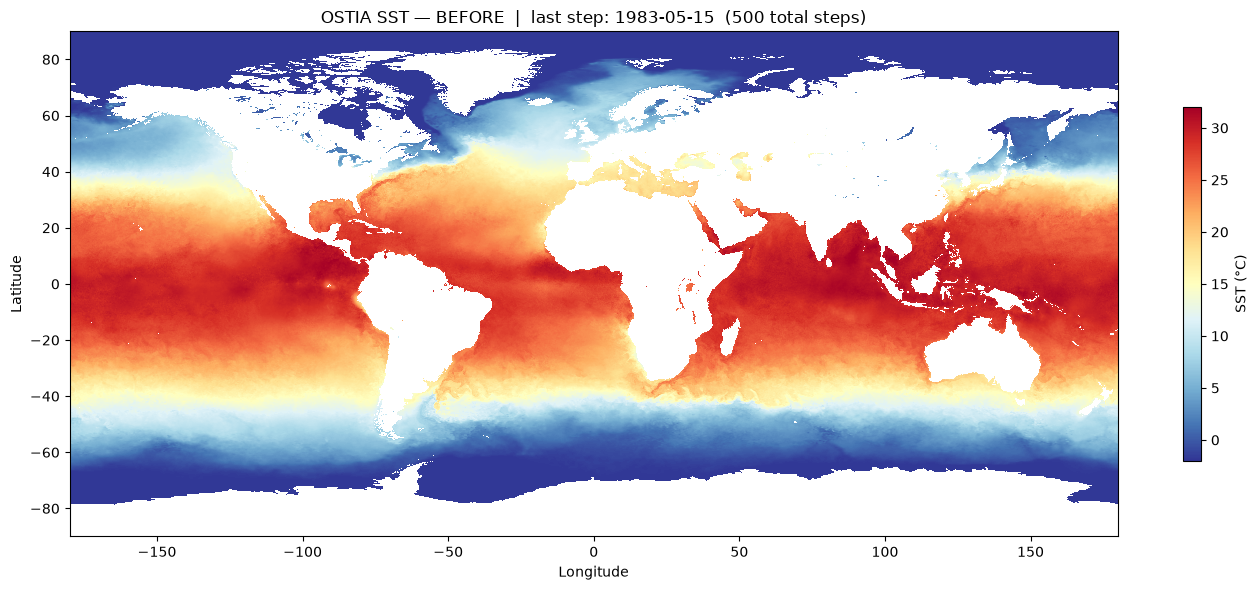

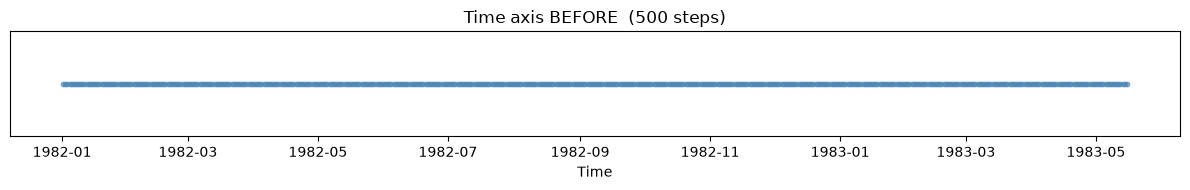

In [3]:
ds_before = open_store()
n_before  = ds_before.sizes["time"]
print(f"{n_before} steps  |  {ds_before.time.values[0]} → {ds_before.time.values[-1]}")
plot_sst(ds_before, "OSTIA SST — BEFORE")
plot_time_axis(ds_before, title="Time axis BEFORE")

---
▶ **Send your SQS messages in the background now, then run the cells below.**

---

## After — re-read store once append has landed

  2026-10-26T16:46:58.001335Z  WARN aws_runtime::env_config::normalize: profile [claude] ignored; sections in the AWS config file (other than [default]) must have a prefix i.e. [profile my-profile]
    at /Users/runner/.cargo/registry/src/index.crates.io-1949cf8c6b5b557f/aws-runtime-1.7.2/src/env_config/normalize.rs:121

  2026-10-26T16:46:58.001357Z  WARN aws_runtime::env_config::normalize: profile [cumulus-sandbox] ignored; sections in the AWS config file (other than [default]) must have a prefix i.e. [profile my-profile]
    at /Users/runner/.cargo/registry/src/index.crates.io-1949cf8c6b5b557f/aws-runtime-1.7.2/src/env_config/normalize.rs:121

  2026-10-26T16:46:58.001362Z  WARN aws_runtime::env_config::normalize: profile [service-ops] ignored; sections in the AWS config file (other than [default]) must have a prefix i.e. [profile my-profile]
    at /Users/runner/.cargo/registry/src/index.crates.io-1949cf8c6b5b557f/aws-runtime-1.7.2/src/env_config/normalize.rs:121

  2026-10-26T16:4

1500 steps  (+1000)  |  1982-01-01T12:00:00.000000000 → 1986-02-08T12:00:00.000000000


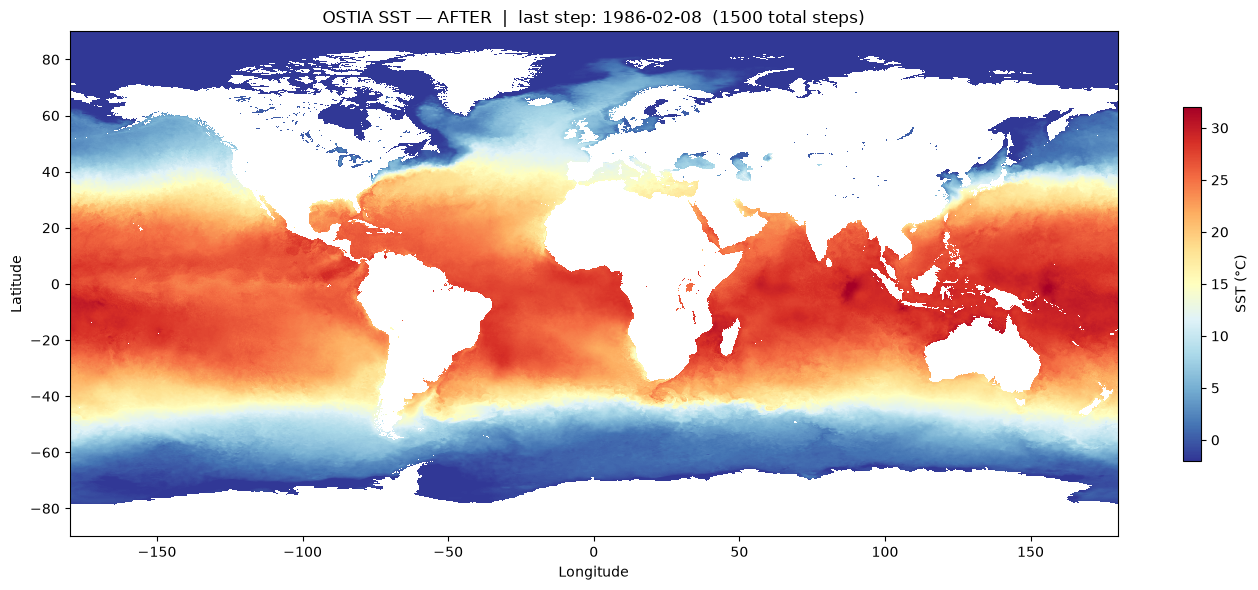

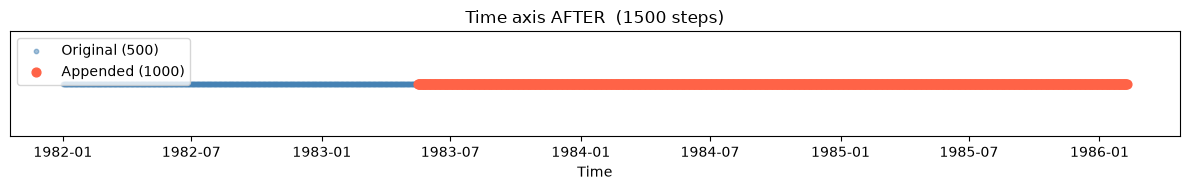

In [9]:
ds_after = open_store()
n_after  = ds_after.sizes["time"]
print(f"{n_after} steps  (+{n_after - n_before})  |  {ds_after.time.values[0]} → {ds_after.time.values[-1]}")
plot_sst(ds_after, "OSTIA SST — AFTER")
plot_time_axis(ds_after, new_from=n_before, title="Time axis AFTER")

### Side-by-side comparison

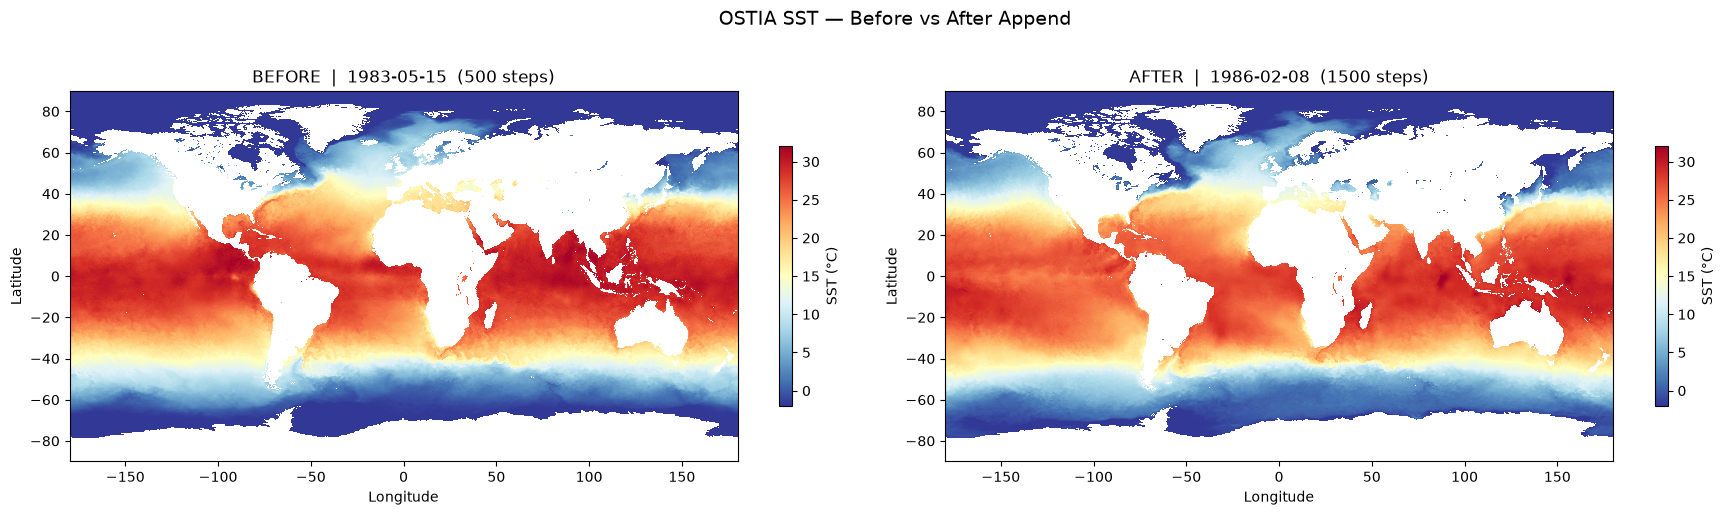

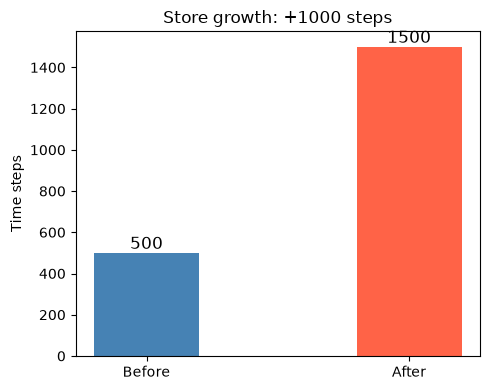

In [10]:
sst_before = ds_before["analysed_sst"].isel(time=-1).values - 273.15
sst_after  = ds_after["analysed_sst"].isel(time=-1).values - 273.15
t_before   = str(ds_before.time.values[-1])[:10]
t_after    = str(ds_after.time.values[-1])[:10]

fig, axes = plt.subplots(1, 2, figsize=(18, 5))
for ax, data, label, t, n in [
    (axes[0], sst_before, "BEFORE", t_before, n_before),
    (axes[1], sst_after,  "AFTER",  t_after,  n_after),
]:
    img = ax.imshow(data, origin="lower", aspect="auto",
                    extent=[-180, 180, -90, 90],
                    cmap="RdYlBu_r", vmin=-2, vmax=32, interpolation="nearest")
    plt.colorbar(img, ax=ax, label="SST (°C)", shrink=0.7)
    ax.set_title(f"{label}  |  {t}  ({n} steps)")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
plt.suptitle("OSTIA SST — Before vs After Append", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(["Before", "After"], [n_before, n_after], color=["steelblue", "tomato"], width=0.4)
for bar, val in zip(bars, [n_before, n_after]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(val), ha="center", va="bottom", fontsize=12)
ax.set_ylabel("Time steps")
ax.set_title(f"Store growth: +{n_after - n_before} steps")
plt.tight_layout()
plt.show()

### Verify time axis is monotonic

In [ ]:
times     = ds_after["time"].values
diffs     = np.diff(times.astype("int64"))
monotonic = bool(np.all(diffs > 0))
print(f"Monotonically increasing: {monotonic}")
print(f"Min gap: {diffs.min() / 1e9 / 86400:.1f} days")
print(f"Max gap: {diffs.max() / 1e9 / 86400:.1f} days")